## PCA Exploratory
Notebook to exploratory analysis on EOFs obtained from zonally symmetric simulations.

In [1]:
import sys
import os
# REMOTE - So can access functions in isca_tools which is in home/Isca directory
# sys.path.append(os.path.join(os.environ['HOME'], 'Isca'))
# LOCAL - So can access functions in isca_tools which is in StAndrews/Isca
sys.path.append(os.environ['PWD'])
import isca_tools
from isca_tools.utils.decomposition import pca_on_xarray
from isca_tools.plot import update_linewidth, update_fontsize
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from scipy import optimize

# Use custom matplotlib style for publishing
plt.style.use('/Users/joshduffield/Documents/StAndrews/Isca/jobs/tau_sweep/aquaplanet/publish_figures/publish.mplstyle')
ax_linewidth = plt.rcParams['axes.linewidth']

In [2]:
# Load dataset
exp_name = 'tau_sweep/aquaplanet/depth=1/k=1'
ds = isca_tools.load_dataset(exp_name, first_month_file=25)[['ps', 'ucomp', 'height', 't_surf']].load()
namelist = isca_tools.load_namelist(exp_name)  # Need this for albedo_value
albedo = namelist['mixed_layer_nml']['albedo_value']
tau_sw = namelist['two_stream_gray_rad_nml']['atm_abs']
tau_lw = namelist['two_stream_gray_rad_nml']['odp']

/Users/joshduffield/Documents/StAndrews/Isca/isca_tools/utils/load.py:75: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  d = xr.open_mfdataset(data_file, concat_dim='time', combine='nested',


In [5]:
def daily_climatology_anomalies(data, dayofyear, window=31):
    dayofyear = dayofyear.sel(time=data.time).rename("dayofyear")
    n_days_year = int(dayofyear.max().item())

    if window < 1 or window % 2 != 1 or window > n_days_year:
        raise ValueError(
            f"window must be an odd integer between 1 and {n_days_year}"
        )

    data = data.assign_coords(dayofyear=dayofyear)
    year_days = np.arange(1, n_days_year + 1)

    raw_clim = (
        data.groupby("dayofyear")
        .mean("time")
        .reindex(dayofyear=year_days)
    )

    counts = dayofyear.groupby(dayofyear).count(dim='time').reindex(
        dayofyear=year_days, fill_value=0
    )
    if bool((counts == 0).any()):
        raise ValueError("Every day of year must have at least one sample")

    half = window // 2
    smooth_clim = xr.concat(
        [
            raw_clim.roll(dayofyear=offset, roll_coords=False)
            for offset in range(-half, half + 1)
        ],
        dim="window_offset",
    ).mean("window_offset", skipna=False)

    anomaly = data.groupby("dayofyear") - smooth_clim
    anomaly = anomaly.reset_coords("dayofyear", drop=True)

    return anomaly, smooth_clim, raw_clim

def combine_hemisphere(var, dayofyear, lat_min=0, lat_dim='lat'):
    nh = var.where(var[lat_dim] >= lat_min, drop=True)
    sh = var.where(var[lat_dim] <= -lat_min, drop=True)
    sh = sh.assign_coords({lat_dim: -sh[lat_dim]})
    # Put both hemispheres in ascending latitude order.
    # nh = nh.sortby(lat_dim)
    sh = sh.sortby(lat_dim)

    if not bool((nh[lat_dim].diff(lat_dim) > 0).all()):
        raise ValueError("NH latitudes must be strictly ascending")
    if not bool((sh[lat_dim].diff(lat_dim) > 0).all()):
        raise ValueError("SH latitudes must be strictly ascending")
    if sh.sizes[lat_dim] != nh.sizes[lat_dim]:
        raise ValueError("NH and SH must have the same number of latitude points")

    # Use NH's exact coordinates to avoid tiny alignment differences.
    sh = sh.assign_coords({lat_dim: nh[lat_dim]})

    pooled = xr.concat(
        [nh, sh],
        dim=xr.IndexVariable("hemisphere", ["NH", "SH"]),
        join="exact",
    )

    # Have one universal time based on NH.
    doy_use = dayofyear.sel(time=var.time)
    # SH gets a half-year shift; NH stays unchanged.
    n_day_year = int(doy_use.max().item())
    offset = xr.where(pooled.hemisphere == "SH", n_day_year // 2, 0)

    doy_nh = (
    (doy_use - 1 + offset) % n_day_year + 1
    ).transpose("hemisphere", "time")

    # pooled = pooled.assign_coords(dayofyear_nh=doy_nh)
    return pooled, doy_nh

def month_index_ranges(n_days_year=360, jan1_index=1):
    """Return each month's inclusive start/end day indices for a 360-day calendar."""
    if n_days_year != 360:
        raise ValueError("This function expects a 360-day calendar.")

    month_names = [
        "January", "February", "March", "April", "May", "June",
        "July", "August", "September", "October", "November", "December",
    ]
    days_per_month = 30

    return {
        name: [jan1_index + i * days_per_month,
               jan1_index + (i + 1) * days_per_month - 1]
        for i, name in enumerate(month_names)
    }


def sign_convention(results, lat_polar=65):
    # Sign convention: positive index means lower polar-cap pressure.
    polar_pattern = results['pattern'].where(results['pattern'].lat >= lat_polar, drop=True)
    polar_mean = polar_pattern.weighted(
        np.cos(np.deg2rad(polar_pattern.lat))
    ).mean("lat")

    sign = xr.where(polar_mean > 0, -1.0, 1.0)
    results['pattern'] = results['pattern'] * sign
    results['eof'] = results['eof'] * sign
    results['pc'] = results['pc'] * sign
    results['index'] = results['index'] * sign
    return results

def get_pattern(eof, pc_std, weight):
    # Pattern is such that if multiplied by PC normalised by its standard deviation, it gives the best reconstruction.
    # I.e., pattern * (pc / pc_std) = reconstruct
    # This is good so the amplitude is within the pattern not the pc coefficient.
    return eof / weight * pc_std

### Preprocess the data before PCA.
PCA is performed on anomalies of zonal-mean surface pressure. Preprocessing requires following steps:
* Find mean climatology
* Obtain anomalies from the climatology and smooth over 15 days to remove the noisy day to day weather
* Combine hemispheres by shifting SH days by 180 days (half a year)
* Weight by latitude

In [32]:
# Must correspond to the actual start of a January in your model calendar.
jan1_time = 0.0
n_days_year = 360.0
window_clim = 31    # This is the window for smoothing the climatology, not the anomalies.
window_anom = 15    # This is the window for smoothing the anomalies, not the climatology.
lat_min = 30.0      # Ignore Tropics
month_doy = month_index_ranges()
fit_season = None

dayofyear = xr.DataArray(
    np.floor((ds.time.values - jan1_time) % n_days_year).astype(int) + 1,
    dims="time",
    coords={"time": ds.time},
    name="dayofyear",
)

# Get climatology and anomalies, then smooth the anomalies.
ds_anom, ds_clim_smooth, ds_clim_raw = daily_climatology_anomalies(ds.mean(dim='lon'), dayofyear, window=window_clim)
ds_anom_smooth = (
    ds_anom
    .rolling(time=window_anom, center=True)
    .mean()
    .dropna("time", how="any")
)

# Combine hemispheres
ds_anom_smooth, doy_nh = combine_hemisphere(ds_anom_smooth, dayofyear=dayofyear, lat_min=lat_min)

# Select season
if fit_season == 'winter':
    valid = (doy_nh >= month_doy['December'][0]) | (doy_nh <= month_doy['February'][1])
elif fit_season == 'summer':
    valid = (doy_nh >= month_doy['June'][0]) & (doy_nh <= month_doy['August'][1])
else:
    valid = None   # entire year

# Area-weighted covariance PCA, not correlation PCA.
weight = np.sqrt(np.cos(np.deg2rad(ds_anom_smooth.lat)))
ps_use = ds_anom_smooth.ps * weight

results = {}
results['eof'], results['pc'], results['weighted_ref_mean'], _, results['variance'], results['variance_frac'] = \
    pca_on_xarray(ps_use, 4, standardize=False, valid=valid, feature_dim_name='lat', reference_mean=True)

# Calculate index and physical pressure pattern per one-standard-deviation index. 
# So reconstruction is sum of index * pattern where sum over mode.
pc_fit = results['pc'] if valid is None else results['pc'].where(valid)
pc_mean = pc_fit.mean(['time', 'hemisphere'])
pc_std = pc_fit.std(['time', 'hemisphere'], ddof=1)
results['pattern'] = get_pattern(results['eof'], pc_std, weight)
results['index'] = index = (results['pc'] - pc_mean) / pc_std
results = sign_convention(results)

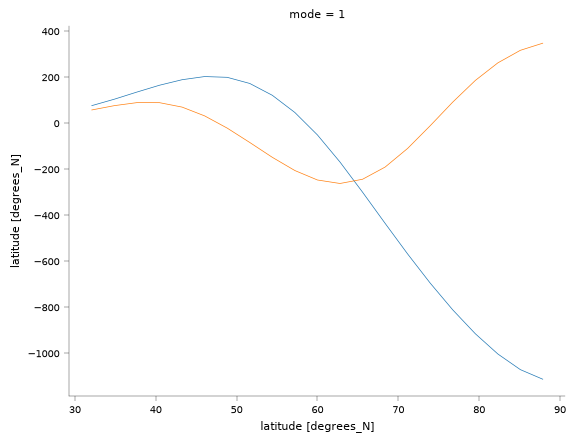

In [33]:
results['pattern'].sel(mode=0).plot()
results['pattern'].sel(mode=1).plot()

### Sanity Check
Below, I do a sanity check to make sure the EOFs resconstruct the full pressure anomaly.

(0.0, 100.0)

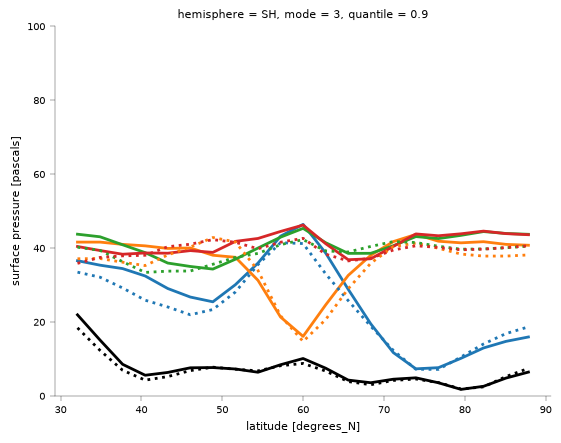

In [23]:
def error_explained_by_mode(anom, pattern, index, valid=None, 
                          sample_dims=("time")):
    # Physical pressure contribution from EACH mode.
    # Dimensions: (hemisphere, time, mode, lat), in some order.
    if valid is None:
        valid = ~np.isnan(anom) 
    mode_reconstruction = index * pattern

    anom, mode_reconstruction = xr.align(
        anom, mode_reconstruction, join="inner"
    )

    # Apply the exact fitting mask.
    # If you fitted all times, you can omit these two lines.
    anom = anom.where(valid)
    mode_reconstruction = mode_reconstruction.where(valid)

    mae_sum = np.abs(anom - mode_reconstruction.sum(dim='mode')).mean(dim=sample_dims)
    mae_by_mode = np.abs(anom - mode_reconstruction).mean(dim=sample_dims)
    norm_factor = np.abs(anom).quantile(0.9, dim=sample_dims)


    # # Absolute variance contributions, units Pa² if pressure is in Pa.
    # mode_variance = mode_reconstruction.var(
    #     dim=sample_dims, ddof=1
    # )

    # total_variance = anom.var(
    #     dim=sample_dims, ddof=1
    # )

    # # Fraction explained: dimensions (mode, lat).
    # local_fraction = mode_variance / total_variance.where(
    #     total_variance > 0
    # )

    # local_percent = 100 * local_fraction
    return mae_sum/norm_factor*100, mae_by_mode/norm_factor*100, norm_factor


linestyle_use = {'NH': '-', 'SH': ':'}
var_explain = error_explained_by_mode(ds_anom_smooth.ps, results['pattern'], results['index'], valid)
for key in var_explain[0].hemisphere:
    var_explain[0].sel(hemisphere=key).plot(color='k', linestyle=linestyle_use[str(key.values)])
    for i in var_explain[1].mode:
        var_explain[1].sel(hemisphere=key, mode=i).plot(color=f'C{int(i)}', linestyle=linestyle_use[str(key.values)])
update_linewidth(plt.gcf())
plt.gca().set_ylim(0, 100)

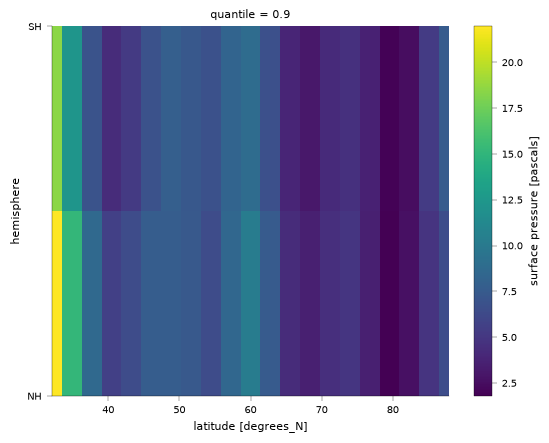

In [24]:
var_explain[0].plot()

In [25]:
(var_exp[1]/var_exp[2]).sel(hemisphere='NH').plot()

NameError: name 'var_exp' is not defined

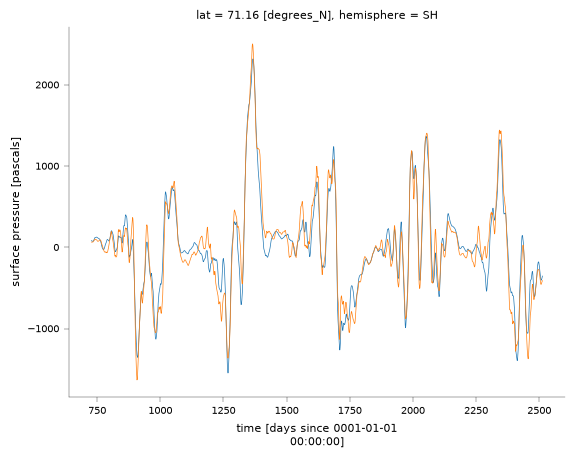

In [27]:
lat_use = 70
hem_use = 'SH'
var = (results['index'] * results['pattern']).sel(mode=[0]).sum(dim='mode').sel(hemisphere=hem_use).sel(lat=lat_use, method='nearest')
var.plot()
ds_anom_smooth.ps.sel(hemisphere=hem_use).sel(lat=lat_use, method='nearest').plot()

### Geostrophic Wind
Get the geostrophic wind associated with the obtained surface pressure. Basically proportional to differential of surface pressure with respect to latitude.

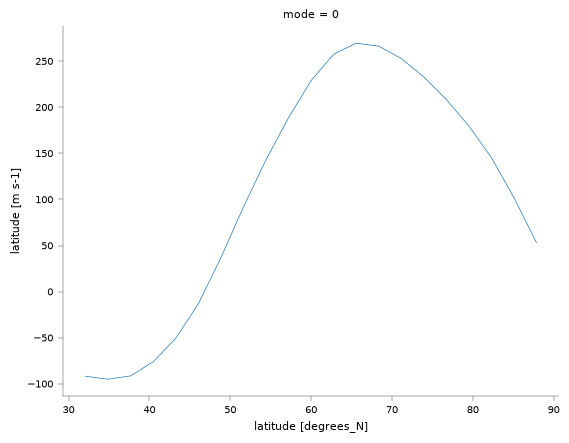

In [28]:

p_pattern = results['pattern'].sel(mode=0)*100      # In units of Pa.
# Use your model's actual planetary constants if different.
a = 6.371e6
Omega = 7.292115e-5

# Simple reference-density approximation, kg m-3.
# Can instead be a latitude-dependent DataArray.
rho_s = 1.2

phi = np.deg2rad(p_pattern.lat)
f = 2 * Omega * np.sin(phi)

# differentiate("lat") gives Pa per DEGREE:
# multiply by 180/pi to obtain Pa per RADIAN.
dp_dphi = p_pattern.differentiate("lat", edge_order=2) * 180 / np.pi

u_g_pattern = -dp_dphi / (rho_s * f * a)
u_g_pattern.name = "geostrophic_zonal_wind_pattern"
u_g_pattern.attrs["units"] = "m s-1"
u_g_pattern.attrs["description"] = "Wind anomaly per +1 SD annular index"

u_g_pattern.plot()

### Regression onto EOF

In [11]:
def regress_on_index(field, index, sample_dims=("time",), valid=None):
    """Regress field onto index, including an intercept.

    Args:
        field (xr.DataArray): Physical field or anomaly
        index (xr.DataArray): Index broadcastable against field, e.g. (time,).
        sample_dims (tuple, optional): Dimensions over which to fit the regression. Defaults to ("time",).
        valid (xr.DataArray, optional): Optional boolean mask selecting fitting samples. Defaults to None.

    Returns:
        xr.DataArray: Dataset containing slope, correlation, intercept, and n.
    """
    field, index = xr.align(field, index, join="inner")

    if valid is not None:
        valid = valid.fillna(False).astype(bool)
        field = field.where(valid)
        index = index.where(valid)

    # Pairwise finite samples at each output location.
    good = np.isfinite(field) & np.isfinite(index)
    y = field.where(good)
    x = index.where(good)

    xm = x.mean(sample_dims)
    ym = y.mean(sample_dims)

    dx = x - xm
    dy = y - ym

    sxx = (dx**2).sum(sample_dims)
    syy = (dy**2).sum(sample_dims)
    sxy = (dx * dy).sum(sample_dims)

    slope = (sxy / sxx).where(sxx > 0)
    correlation = (
        sxy / np.sqrt(sxx * syy)
    ).where((sxx > 0) & (syy > 0))

    return xr.Dataset({
        "slope": slope,
        "correlation": correlation,
        "intercept": ym - slope * xm,
        "n": good.sum(sample_dims),
    })

In [66]:
# Get climatology and anomalies, then smooth the anomalies.
var = 

u_anom, u_clim_smooth, _ = daily_climatology_anomalies(ds.ucomp.mean(dim='lon'), dayofyear, window=window_clim)
u_anom_smooth = (
    u_anom
    .rolling(time=window_anom, center=True)
    .mean()
    .dropna("time", how="any")
)
u_anom_smooth = combine_hemisphere(u_anom_smooth, dayofyear=dayofyear, lat_min=lat_min)[0]

height_anom, height_clim_smooth, _ = daily_climatology_anomalies(ds.height.mean(dim='lon'), dayofyear, window=window_clim)
height_anom_smooth = (
    height_anom
    .rolling(time=window_anom, center=True)
    .mean()
    .dropna("time", how="any")
)           
height_anom_smooth = combine_hemisphere(height_anom_smooth, dayofyear=dayofyear, lat_min=lat_min)[0]

In [12]:
reg_u = regress_on_index(
    ds_anom_smooth.ucomp,
    results['index'].sel(mode=0),
    sample_dims=("hemisphere", "time"),
    valid=valid,
)

# reg_z = regress_on_index(
#     height_anom_smooth,
#     index_use,
#     sample_dims=("hemisphere", "time"),
#     valid=valid,
# )

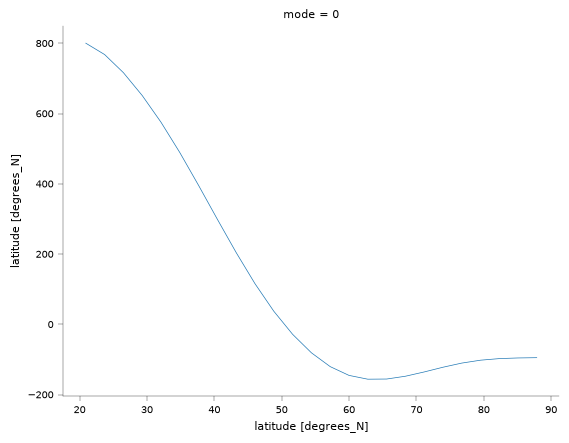

In [60]:
results['pattern'].sel(mode=0).plot()

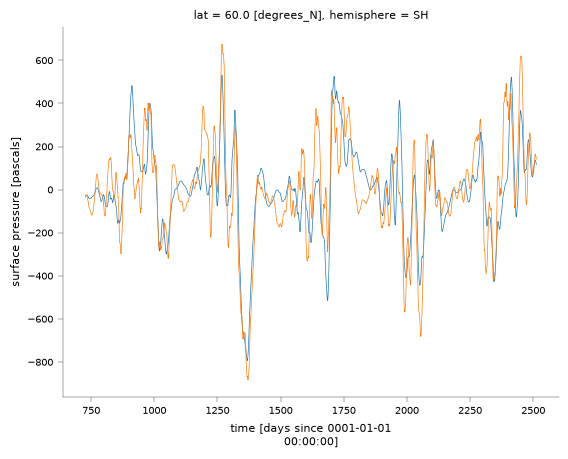

In [78]:
lat_use = 60
var = (results['index'] * results['pattern']).sel(mode=[0]).sum(dim='mode').sel(hemisphere='SH').sel(lat=lat_use, method='nearest')
var.plot()
ds_anom_smooth.ps.sel(hemisphere='SH').sel(lat=lat_use, method='nearest').plot()

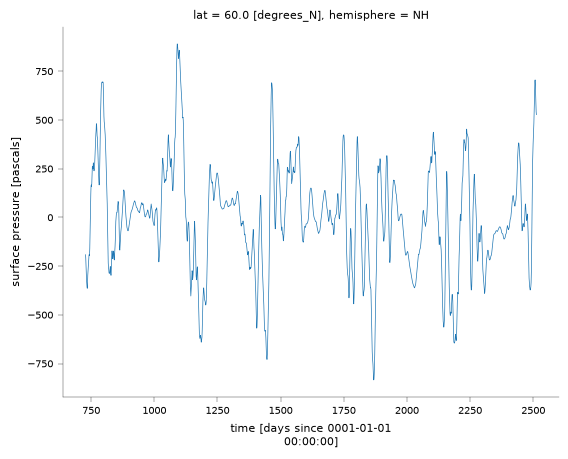

In [15]:
ds_anom_smooth.ps.sel(hemisphere='NH').sel(lat=60, method='nearest').plot()

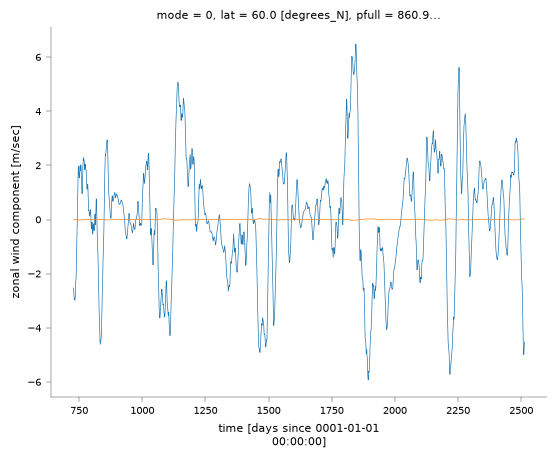

In [115]:
ds_anom_smooth.ucomp.sel(hemisphere='NH').sel(lat=60, pfull=850, method='nearest').plot()
var = reg_u['slope'].sel(lat=60, pfull=850, method='nearest')*results['index'].sel(mode=0).sel(hemisphere='NH')
var.plot()

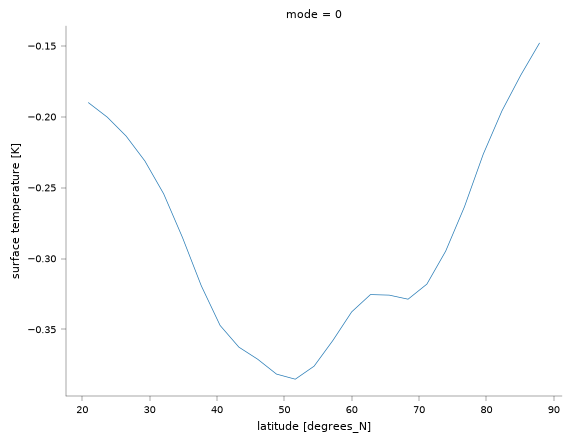

In [99]:
reg_u['intercept'].plot()

In [59]:
# u_nh = u_anom_smooth.where(u_anom_smooth.lat >= lat_min, drop=True)
# height_nh = height_anom_smooth.where(height_anom_smooth.lat >= lat_min, drop=True)

# index_use = results['index'].sel(hemisphere='NH').sel(mode=0)
# reg_u = regress_on_index(u_nh, index_use)
# reg_z = regress_on_index(height_nh, index_use)

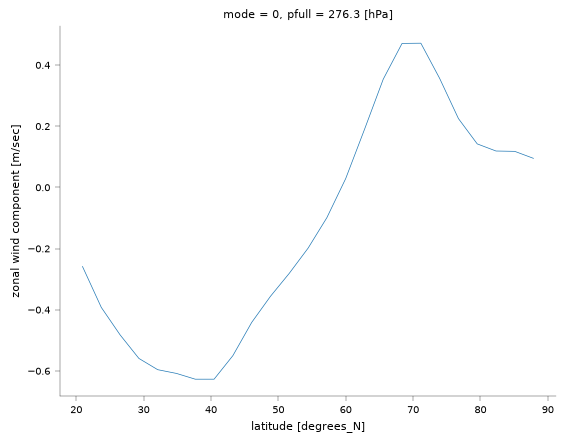

In [88]:
reg_u['correlation'].sel(pfull=250, method='nearest').plot()

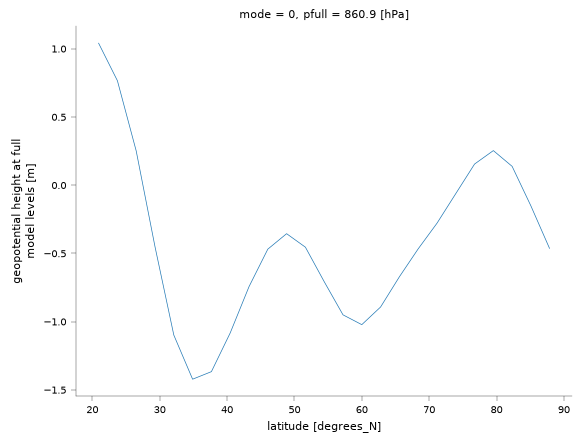

In [83]:
reg_z['slope'].sel(pfull=850, method='nearest').plot()